In [8]:
import DataGen as dtg
import torch
import torch.nn as nn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from tqdm.auto import tqdm
from efficient_kan.kan import KAN
from torch.utils.data import TensorDataset, DataLoader, Sampler

import torch.optim as optim
from architecture import Architecture

SEED = 42

In [9]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using '{DEVICE}' device.")

Using 'cpu' device.


## Obtenção do conjunto de dados

### Definindo o espaço de velocidade


In [10]:
X_POINTS = 30
Z_POINTS = 30
Y_POINTS = 1

X_DISTANCE = 1
Y_DISTANCE = 1
Z_DISTANCE = 1


In [11]:
dg_over = 10 / 100
xover = np.arange(0, 2900 / 1000 + dg_over, dg_over)
zover = np.arange(0, 2900 / 1000 + dg_over, dg_over)

v_line_z = 1.5 + zover
v_line_x = np.tile(0.3 * xover, (len(zover), 1))
v_depth = np.tile(v_line_z[:, np.newaxis], (1, len(xover))) + v_line_x

v_depth = v_depth.reshape(X_POINTS,Z_POINTS,Y_POINTS) # necessário adicionar a terceira dimensão para o modelo do Solver

In [12]:
df = dtg.generateMultipleData(
    nPoints = (X_POINTS, Z_POINTS, Y_POINTS), 
    nodeDistances = (X_DISTANCE, Y_DISTANCE, Z_DISTANCE),
    velocityModel = v_depth,
    sourceOriginInterval= [[0,0],[4,4]])

In [13]:
df.head(5)

,x,z,travel_time,source_x0,source_z0
0,0,0,0.000000,0,0
1,0,1,0.653595,0,0
2,0,2,1.298810,0,0
3,0,3,1.933169,0,0
4,0,4,2.556145,0,0


In [14]:
features = ['x', 'z', 'source_x0', 'source_z0']
target = ['travel_time']

### Separando o conjunto em Treinamento, Validação e Teste

In [15]:
initial_conditions = df[['source_x0', 'source_z0']].drop_duplicates().reset_index(drop=True)
aux = initial_conditions.copy()

ic_train = aux.sample(frac=0.6, random_state=SEED)
ic_val = aux.drop(ic_train.index).sample(frac=0.5, random_state=SEED)
ic_test = aux.drop(list(ic_train.index) + list(ic_val.index))

print("Train Initial Conditions:", len(ic_train))
print("Validation Initial Conditions:", len(ic_val))
print("Test Initial Conditions:", len(ic_test))

Train Initial Conditions: 15
Validation Initial Conditions: 5
Test Initial Conditions: 5


In [16]:
df_train = df.merge(ic_train, on=['source_x0', 'source_z0'], how='inner')
df_val = df.merge(ic_val, on=['source_x0', 'source_z0'], how='inner')
df_test = df.merge(ic_test, on=['source_x0', 'source_z0'], how='inner')

print("Train Size:", len(df_train))
print("Validation Size:", len(df_val))
print("Test Size:", len(df_test))

Train Size: 13500
Validation Size: 4500
Test Size: 4500


In [17]:
from itertools import cycle
import random


class BalancedBatchSampler(Sampler):
    def __init__(self, dataset, batch_size, t_index=3, shuffle=True):
        """
    A sampler that generates balanced batches from a dataset, ensuring that each batch contains
    an equal number of samples with a specific target value.
    Args:
        dataset (Dataset): The dataset to sample from.
        batch_size (int): The number of samples per batch.
        t_index (int, optional): The index of the target value in the dataset samples. Default is 4.
        shuffle (bool, optional): Whether to shuffle the batch indices. Default is True.
        
    Attributes:
        dataset (Dataset): The dataset to sample from.
        batch_size (int): The number of samples per batch.
        t_index (int): The index of the target value in the dataset samples.
        shuffle (bool): Whether to shuffle the batch indices.
        t_zero_indices (list): Indices of samples with target value equal to 0.
        non_t_zero_indices (list): Indices of samples with target value not equal to 0.
        
    Methods:
        __iter__(): Generates balanced batches of indices.
        __len__(): Returns the number of batches.
    """
        if batch_size % 2 != 0 or batch_size <= 0:
            raise ValueError("batch_size deve ser um número inteiro positivo e par.")
        
        self.dataset = dataset
        self.batch_size = batch_size
        self.t_index = t_index
        self.shuffle = shuffle

        # Dividir o dataset em duas partes: com t=0 e sem t=0
        self.t_zero_indices = []
        self.non_t_zero_indices = []

        for i in range(len(self.dataset)):
            data = self.dataset[i]
            try:
                t_sample = data[0][self.t_index]
            except (IndexError, TypeError):
                raise ValueError(f"O índice de tempo t_index={self.t_index} não é válido.")
            if t_sample == 0:
                self.t_zero_indices.append(i)
            else:
                self.non_t_zero_indices.append(i)

        if not self.t_zero_indices or not self.non_t_zero_indices:
            raise ValueError("Não há amostras suficientes em cada classe para criar batches balanceados.")

    def __iter__(self):
        if self.shuffle:
            random.shuffle(self.t_zero_indices)
            random.shuffle(self.non_t_zero_indices)

        t_zero_iter = cycle(self.t_zero_indices)
        non_t_zero_iter = cycle(self.non_t_zero_indices)

        num_batches = len(self.dataset) // self.batch_size

        for _ in range(num_batches):
            t_zero_batch = [next(t_zero_iter) for _ in range(2)] # Samples with t=0 per batch
            non_t_zero_batch = [next(non_t_zero_iter) for _ in range(self.batch_size-2)]
            batch_indices = t_zero_batch + non_t_zero_batch

            if self.shuffle:
                random.shuffle(batch_indices)

            yield batch_indices

    def __len__(self):
        return len(self.dataset) // self.batch_size

In [18]:
# Convertendo os dados para tensores
X_train = torch.as_tensor(df_train[features].values, dtype=torch.float32)
y_train = torch.as_tensor(df_train[target].values, dtype=torch.float32)

X_val = torch.as_tensor(df_val[features].values, dtype=torch.float32)
y_val = torch.as_tensor(df_val[target].values, dtype=torch.float32)

X_test = torch.as_tensor(df_test[features].values, dtype=torch.float32)
y_test = torch.as_tensor(df_test[target].values, dtype=torch.float32)

# Criando o Dataset
train_dataset = TensorDataset(X_train, y_train)
val_dataset = TensorDataset(X_val, y_val)
test_dataset = TensorDataset(X_test, y_test)

# Criando um loader para cada conjunto de dados
sampler = BalancedBatchSampler(train_dataset, batch_size=256)
train_loader = DataLoader(dataset=train_dataset,
                          batch_sampler=sampler,
                        #   shuffle=False,
                        #   batch_size=256,
                          )

val_loader = DataLoader(dataset=val_dataset,
                        shuffle=False,
                        batch_size=256
                        )

test_loader = DataLoader(dataset=test_dataset,
                        shuffle=False,
                        batch_size=len(test_dataset)
                        )

In [24]:
# Função de perda física ajustada
def physics_loss_fn(model, input_tensor, *args, **kwargs):
    # Separe as entradas e garanta que as variáveis requerem gradiente
    x = input_tensor[:, 0].view(-1, 1)  # x0
    z = input_tensor[:, 1].view(-1, 1)  # z0
    source_x0 = input_tensor[:, 2].view(-1, 1)  # theta0
    source_z0 = input_tensor[:, 3].view(-1, 1)  # t

    # Certifique-se de que todas as variáveis tenham requires_grad=True para calcular derivadas
    x.requires_grad_(True)
    z.requires_grad_(True)

    # Recalcule yhat usando as variáveis para garantir a conexão
    x_reconstructed = torch.cat([x, z, source_x0, source_z0], dim=1)
    yhat = model(x_reconstructed)
    
    travel_t = yhat[:, 0].view(-1, 1)

    # Calcule v(x, z)
    v = 1.5 + 0.3*x + 0.1*z
    
    # Calcule os gradientes necessários (dt/dx, dt/dz)
    dtdx = torch.autograd.grad(
        outputs=travel_t,  # Derivada de t em relação a x
        inputs=x,
        grad_outputs=torch.ones_like(x),
        create_graph=True,
        retain_graph=True
    )[0]

    dtdz = torch.autograd.grad(
        outputs=travel_t,  # Derivada de t em relação a z
        inputs=z,
        grad_outputs=torch.ones_like(z),
        create_graph=True,
        retain_graph=True
    )[0]


    ## (dt/dx)**2 + (dt/dz)**2 - (1/v)**2
    pde1 = dtdx**2 + dtdz**2 - (1/v)**2

    # Calcular a perda como a soma dos erros quadrados das PDEs
    loss = torch.mean(pde1 ** 2)

    return loss

In [25]:
def sin():
    return torch.sin

In [26]:
torch.manual_seed(42)
input_size = len(features)
output_size = len(target)
model = KAN([input_size, 6, 5, 4, output_size], grid_size=8,
            spline_order=3, base_activation=sin)

# Defines optimizer to update the parameters
optimizer = optim.Adam(model.parameters(),
                        lr=1e-3)


# Defines a MSE loss function
loss_fn = torch.nn.MSELoss(reduction='mean')

In [27]:
arch = Architecture(model, loss_fn, physics_loss_fn,
                    optimizer, lamb=1e-3, lamb_l1=1e-3,
                    lamb_entropy=2, lambda_physics=1e-3)
arch.set_loaders(train_loader, val_loader)

In [38]:
n_epochs = 100
arch.train(n_epochs=n_epochs, seed=SEED)

Training PIKAN: 100%|██████████| 110/110 [04:15<00:00,  2.56s/it, data_loss=6.19, loss=6.21, physics_loss=3.09e-6, val_loss=6.29]


In [39]:
arch.save_checkpoint(f"output/checkpoint_{n_epochs}epochs.pt")

C:\Users\2052180\AppData\Local\Temp\ipykernel_4932\4065197815.py:2: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


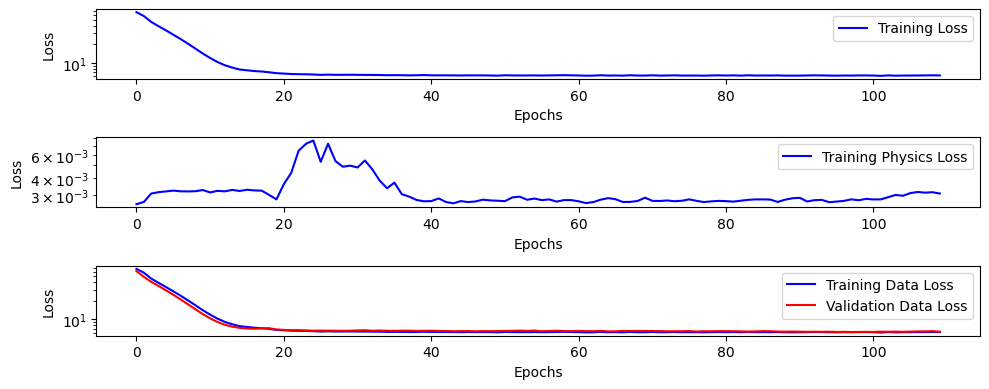

In [40]:
fig = arch.plot_losses()
fig.show()

In [41]:
predictions = arch.predict(df_test[features].values)
df_pred = pd.DataFrame(predictions, columns=target)
df_pred = df_test[features].join(df_pred)
df_pred.head()

,x,z,source_x0,source_z0,travel_time
0,0,0,2,0,1.851596
1,0,1,2,0,1.797226
2,0,2,2,0,7.781336
3,0,3,2,0,7.685315
4,0,4,2,0,7.361061


In [37]:
df_filtrado = df[(df['x'] == 0) & (df['source_x0'] == 2)]
print(df_filtrado)

    x   z  travel_time  source_x0  source_z0
0   0   0     1.277778          2          0
1   0   1     1.574983          2          0
2   0   2     1.945218          2          0
3   0   3     2.377457          2          0
4   0   4     2.848409          2          0
.. ..  ..          ...        ...        ...
25  0  25    10.075602          2          4
26  0  26    10.448500          2          4
27  0  27    10.812598          2          4
28  0  28    11.168242          2          4
29  0  29    11.515783          2          4

[150 rows x 5 columns]


In [42]:
score(df_pred[target].values, df_test[target].values)

NameError: name 'score' is not defined